## Random Forest

### 0. Data

In [11]:
url = "http://byungwan.com/class/Coupon_Sample.xlsx"

import pandas as pd

coupon = pd.read_excel(url)

coupon.head()

,CID,Gender,Age,CClass,Discount,Visits,Email,SMS,MStatus,Purchases,Sales
0,1,0,41,2,0,1,0,1,1,1,0.92
1,2,0,41,1,0,0,0,0,0,0,0.00
2,3,0,30,2,0,3,0,0,0,1,1.54
3,4,0,28,2,0,2,0,0,0,2,0.88
4,5,1,24,2,1,5,0,0,0,2,0.53


In [18]:
y = coupon.iloc[:, 4]
x = coupon.iloc[:, [1,2,3,5,6,7,8,9,10]]

In [22]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=123)

### 1. Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

rfc = RandomForestClassifier(n_estimators=5, random_state=0, max_depth=5)
rfc_model = rfc.fit(x_train, y_train)
y_pred = rfc_model.predict(x_test)

metrics.accuracy_score(y_test, y_pred)

0.8733333333333333

### 1.1 Cross Validation

In [26]:
from sklearn.model_selection import cross_val_score

scores= cross_val_score(rfc, x, y, cv=10)

In [29]:
import numpy as np

float(np.mean(scores))

0.8918367346938776

### 1.2 Balancing

In [31]:
coupon["Discount"].value_counts()

Discount
0    377
1    122
Name: count, dtype: int64

In [32]:
coupon0 = coupon[coupon["Discount"] == 0]
coupon1 = coupon[coupon["Discount"] == 1]

In [35]:
from sklearn.utils import resample

coupon1_up = resample(coupon1, replace=True, n_samples=377, random_state=0)
coupon_up = pd.concat([coupon0, coupon1_up], axis=0)

coupon_up["Discount"].value_counts()

Discount
0    377
1    377
Name: count, dtype: int64

### 1.3 Feature Importance

In [39]:
fi = rfc_model.feature_importances_
fi

array([0.00910959, 0.06438481, 0.23646519, 0.14616818, 0.01545984,
       0.00806598, 0.00345666, 0.16644404, 0.35044571])

In [40]:
pd.DataFrame({"Variable": x.columns.tolist(), "Feature Importance": fi})

,Variable,Feature Importance
0,Gender,0.009110
1,Age,0.064385
2,CClass,0.236465
3,Visits,0.146168
4,Email,0.015460
5,SMS,0.008066
6,MStatus,0.003457
7,Purchases,0.166444
8,Sales,0.350446


### 1.4 Shapley Value

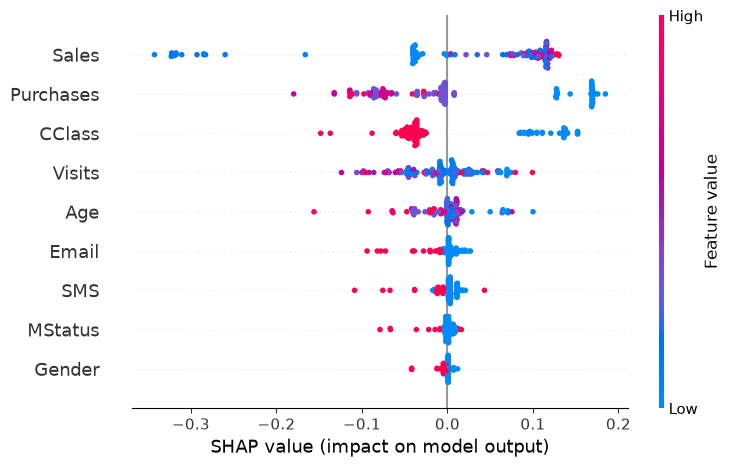

In [42]:
import shap

explainer = shap.TreeExplainer(rfc_model)
shap_exp = explainer(x_test)
shap.plots.beeswarm(shap_exp[:, :, 0])